# BIOMASS L1C vs In-Situ Soil Moisture: Plots

This notebook puts the BIOMASS observations extracted by *Biomass L1C Point Extraction.ipynb* next to the ISMN soil moisture time series of the same stations:

1. **per station and stack:** soil moisture per depth with the BIOMASS acquisition dates, σ⁰ per polarisation, coherence of consecutive pairs, closure phase of consecutive triplets;
2. **all stations:** σ⁰ vs soil moisture at the acquisitions;
3. **all stations:** coherence and interferometric phase of every pair vs the soil moisture change;
4. **all stations:** closure phase of every triplet vs the soil moisture change across the triplet;
5. a per-station summary table (number of acquisitions with soil moisture, soil moisture range, correlation σ⁰–soil moisture).

Nothing is downloaded: it only reads the outputs in `OUTPUT_DIR` and the CSV files in `SM_DIR`. Figures are saved to `OUTPUT_DIR/figures`.

### 1. Packages and Libraries

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import pathlib

### 2. Parameters

- `OUTPUT_DIR`: the same folder used by the availability and extraction notebooks (it contains `acquisitions.csv`, `pairs.csv`, `triplets.csv`, `locations.csv`).
- `SM_DIR`: ISMN time series, one CSV per station named `<network>+<station>.csv`.
- `SM_GOOD_FLAGS`: accepted ISMN quality flags (`G` = good).
- `SM_MAX_DEPTH_M`: sensors not deeper than this are averaged into the near-surface soil moisture matched to each acquisition (nearest hourly value within `SM_TOLERANCE`).
- `PLOT_MAX_DEPTH_M`: deepest sensor drawn in the time-series plots.
- `TIME_MARGIN_DAYS`: soil moisture shown before the first and after the last acquisition of a stack.
- `POINT_IDS`: stations to plot; `None` = all stations in the extraction outputs.

In [2]:
OUTPUT_DIR = pathlib.Path("/media/kle/cropg_hd1/biomass-hackathon-2026-output")   # <- same as in the other notebooks
SM_DIR = pathlib.Path("ISMN_data/temporal")
SM_GOOD_FLAGS = ["G"]
SM_MAX_DEPTH_M = 0.10
SM_TOLERANCE = pd.Timedelta("1h")
PLOT_MAX_DEPTH_M = 0.30
TIME_MARGIN_DAYS = 10
POINT_IDS = None
FIG_DIR = OUTPUT_DIR / "figures"

### 3. Load the BIOMASS extraction outputs

In [3]:
read = lambda name: pd.read_csv(OUTPUT_DIR / name, dtype={"frame": str})
locations, acq, pairs, trips = (read(n) for n in ["locations.csv", "acquisitions.csv", "pairs.csv", "triplets.csv"])
if POINT_IDS:
    locations, acq, pairs, trips = (df[df["point_id"].isin(POINT_IDS)] for df in (locations, acq, pairs, trips))

acq["datetime"] = pd.to_datetime(acq["datetime"], utc=True)
for c in ["date_i", "date_j", "date_k"]:
    for df in (pairs, trips):
        if c in df:
            df[c] = pd.to_datetime(df[c], utc=True)

STACK = ["point_id", "stack_id", "frame"]
print(f"{acq['point_id'].nunique()} station(s), {len(locations)} stack(s), "
      f"{acq['product_id'].nunique()} acquisitions, polarisations: {sorted(acq['pol'].unique())}")

9 station(s), 13 stack(s), 69 acquisitions, polarisations: ['HH', 'HV', 'VH', 'VV']


### 4. Load soil moisture and match it to the acquisitions

Good-quality values of all sensors not deeper than `SM_MAX_DEPTH_M` are averaged per hour; each acquisition gets the nearest hourly value within `SM_TOLERANCE` (`sm`). Pairs and triplets get the values of their acquisitions (`sm_i`, `sm_j`, `sm_k`) and the changes `dsm = sm_j − sm_i` (pairs) and `dsm_ik = sm_k − sm_i` (triplets).

In [4]:
def load_sm(point_id):
    """Soil moisture records (all depths, all flags) of a station 'network/station', or None."""
    network, station = point_id.split("/", 1)
    f = SM_DIR / f"{network}+{station}.csv"
    if not f.exists():
        return None
    d = pd.read_csv(f, usecols=["sensor", "date_time", "soil_moisture", "soil_moisture_flag"],
                    dtype={"soil_moisture_flag": str})
    d = d[d["sensor"].str.contains("_soil_moisture_") & d["soil_moisture"].notna()].copy()
    depth = d["sensor"].str.rsplit("_", n=2, expand=True)
    d["depth_from"], d["depth_to"] = depth[1].astype(float), depth[2].astype(float)
    d["date_time"] = pd.to_datetime(d["date_time"], utc=True)
    d["good"] = d["soil_moisture_flag"].isin(SM_GOOD_FLAGS)
    return d


sm_data = {pid: load_sm(pid) for pid in acq["point_id"].unique()}
missing = [p for p, d in sm_data.items() if d is None]
if missing:
    print("No soil moisture file for:", missing)

epochs = acq.drop_duplicates(STACK + ["datetime"])[STACK + ["datetime", "product_id"]].copy()
matched = []
for pid, g in epochs.groupby("point_id"):
    d = sm_data.get(pid)
    if d is None:
        matched.append(g.assign(sm=np.nan))
        continue
    series = (d[d["good"] & (d["depth_to"] <= SM_MAX_DEPTH_M)]
              .groupby("date_time")["soil_moisture"].mean().rename("sm").reset_index())
    matched.append(pd.merge_asof(g.sort_values("datetime"), series, left_on="datetime", right_on="date_time",
                                 direction="nearest", tolerance=SM_TOLERANCE).drop(columns="date_time"))
epochs = pd.concat(matched, ignore_index=True)
acq = acq.drop(columns="sm", errors="ignore").merge(epochs[STACK + ["datetime", "sm"]], on=STACK + ["datetime"], how="left")

for suffix, df in [("i", pairs), ("j", pairs), ("i", trips), ("j", trips), ("k", trips)]:
    lookup = epochs[STACK + ["datetime", "sm"]].rename(columns={"datetime": f"date_{suffix}", "sm": f"sm_{suffix}"})
    merged = df.merge(lookup, on=STACK + [f"date_{suffix}"], how="left")
    df[f"sm_{suffix}"] = merged[f"sm_{suffix}"].values
pairs["dsm"] = pairs["sm_j"] - pairs["sm_i"]
trips["dsm_ik"] = trips["sm_k"] - trips["sm_i"]

print(f"{epochs['sm'].notna().sum()} of {len(epochs)} acquisitions have near-surface soil moisture "
      f"(≤ {SM_MAX_DEPTH_M:g} m, ±{SM_TOLERANCE}).")
epochs.groupby("point_id")["sm"].agg(n_acquisitions="size", n_with_sm="count", sm_min="min", sm_max="max")

85 of 90 acquisitions have near-surface soil moisture (≤ 0.1 m, ±0 days 01:00:00).


,n_acquisitions,n_with_sm,sm_min,sm_max
point_id,,,,
ROMPS/AbramovGlacier,21,18,0.109,0.130
ROMPS/Baytik,6,6,0.092,0.168
ROMPS/Maydantal,14,14,0.065,0.090
SCAN/Kainaliu,7,7,0.330,0.424
SCAN/Kukuihaele,7,7,0.179,0.254
SCAN/ManaHouse,7,7,0.156,0.168
SCAN/PuuwaiRanch,14,14,0.470,0.502
SCAN/SilverSword,7,7,0.223,0.322
SCAN/WaimeaPlain,7,5,0.266,0.326


### 5. Time series per station and stack

Top: soil moisture per sensor depth (good quality only, mean of the sensors at the same depth) and the near-surface value matched to each BIOMASS acquisition (black dots). Then σ⁰, the coherence of consecutive pairs (plotted at the pair mid-time) and the closure phase of consecutive triplets (plotted at the middle acquisition). Dotted lines mark the acquisitions.

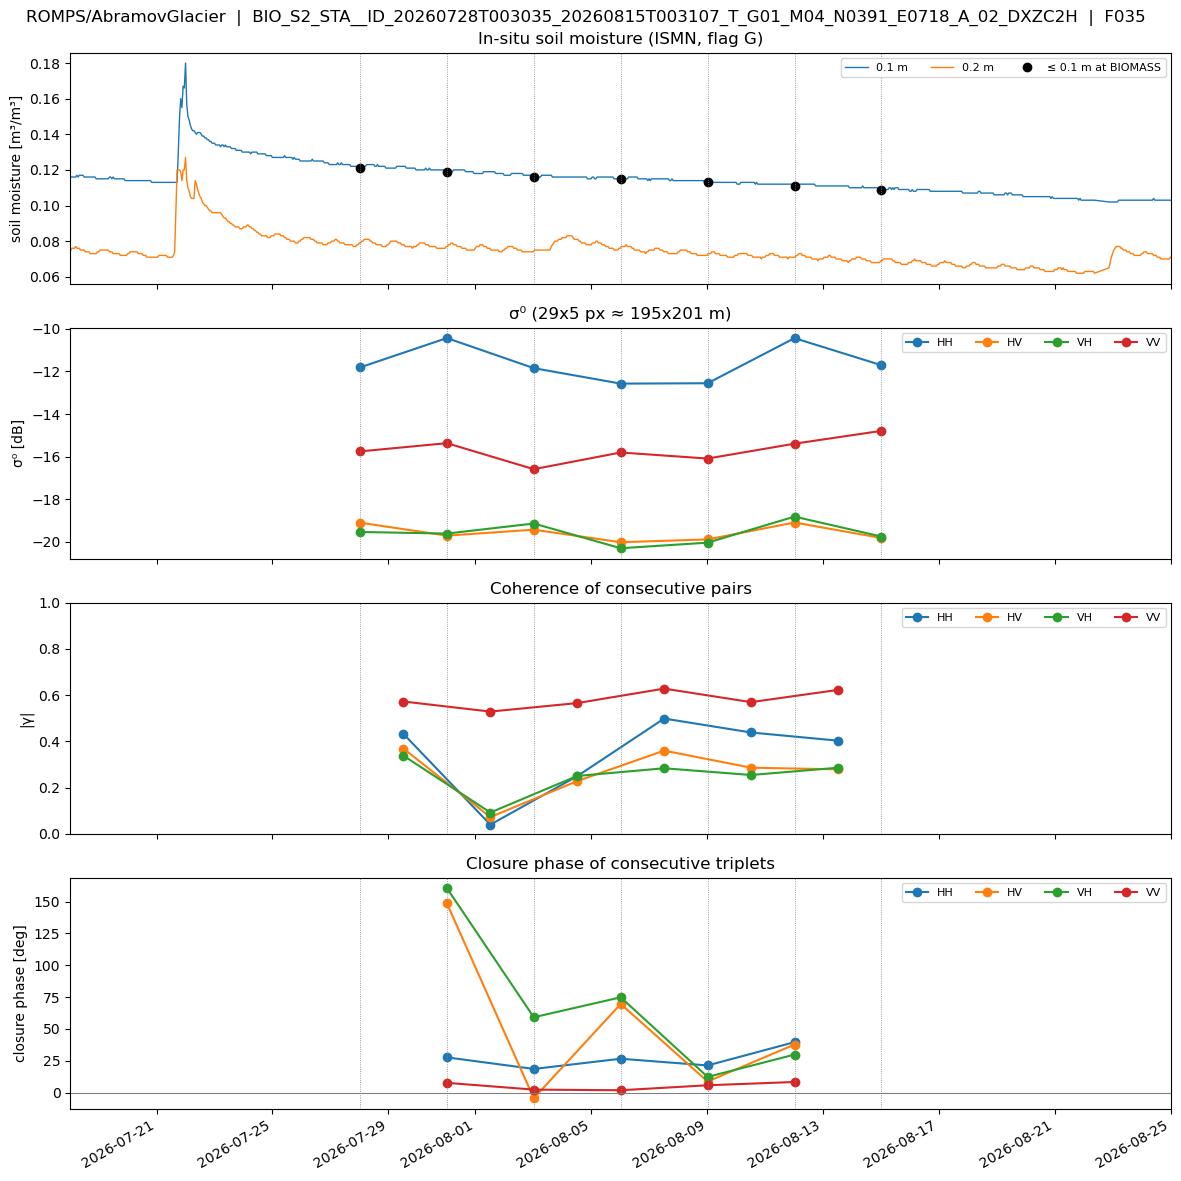

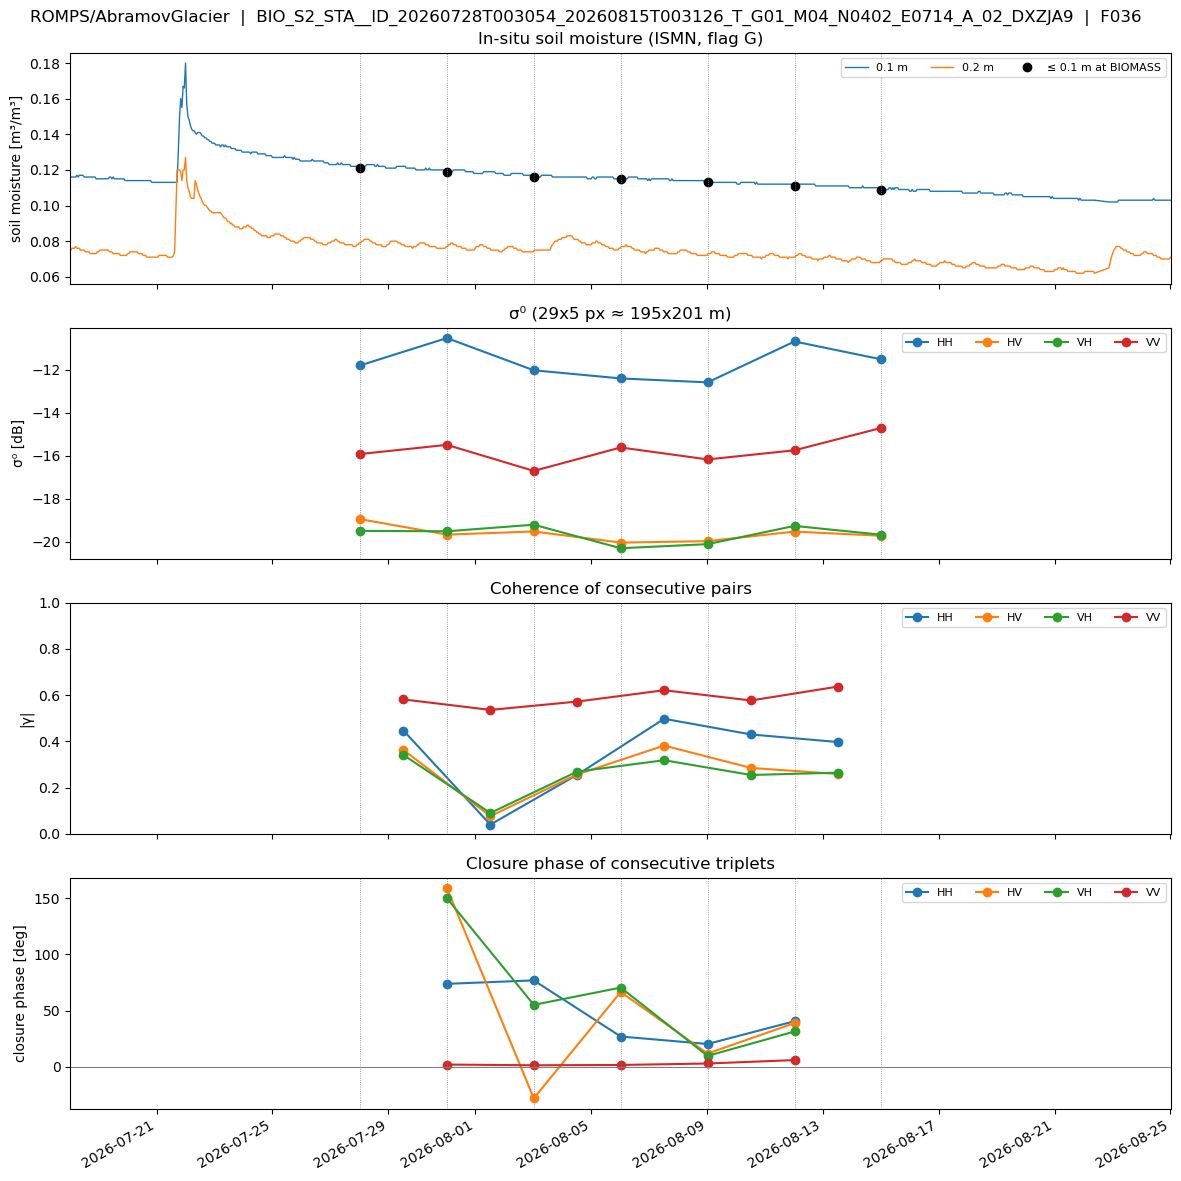

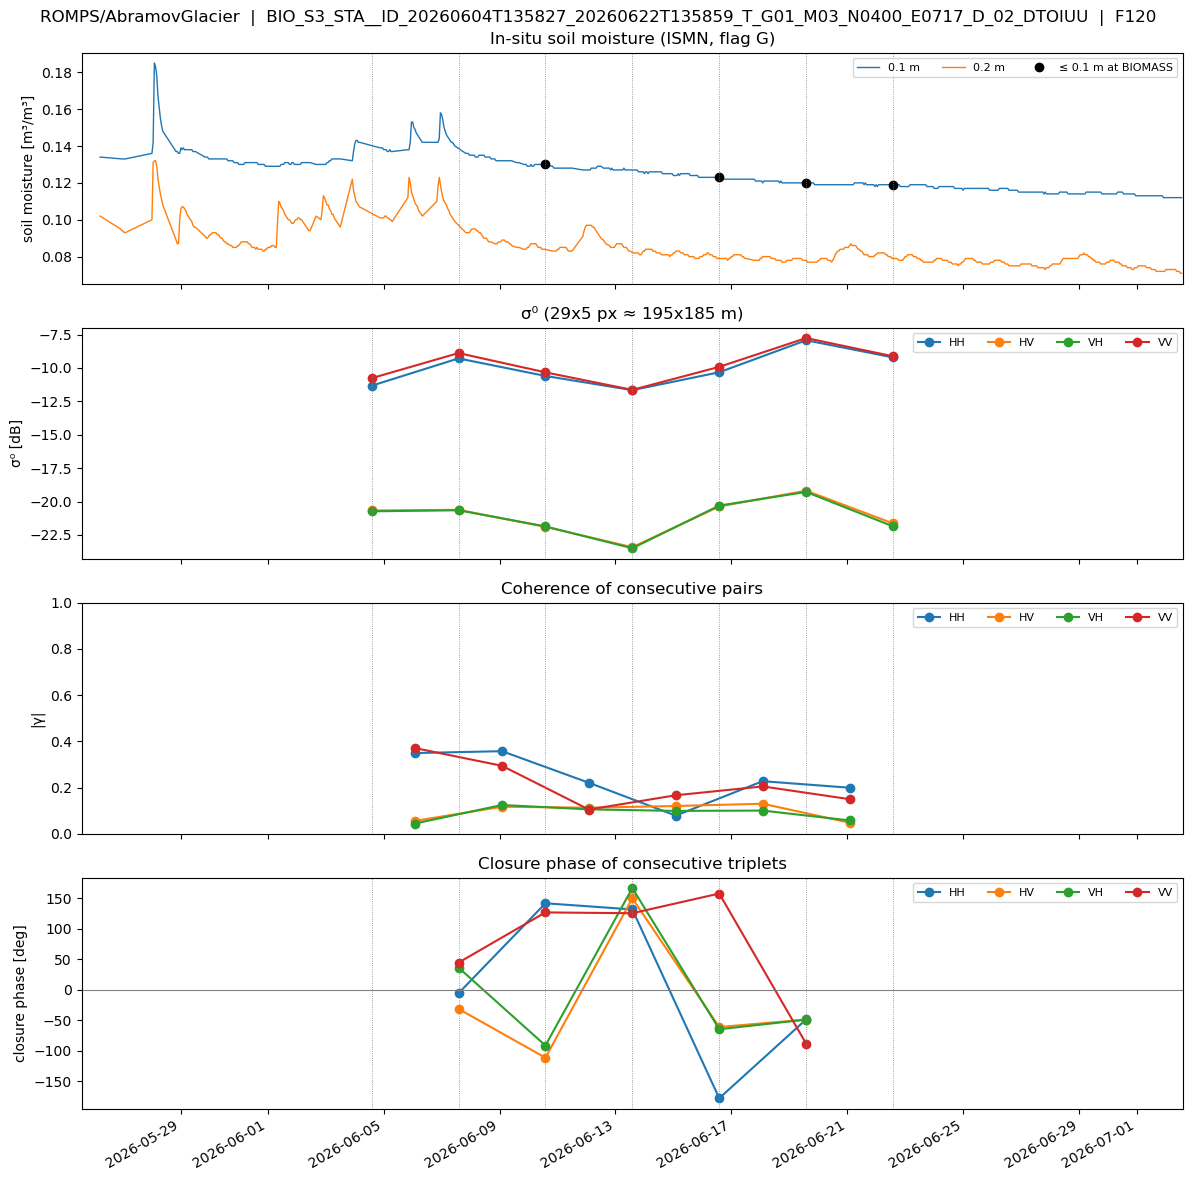

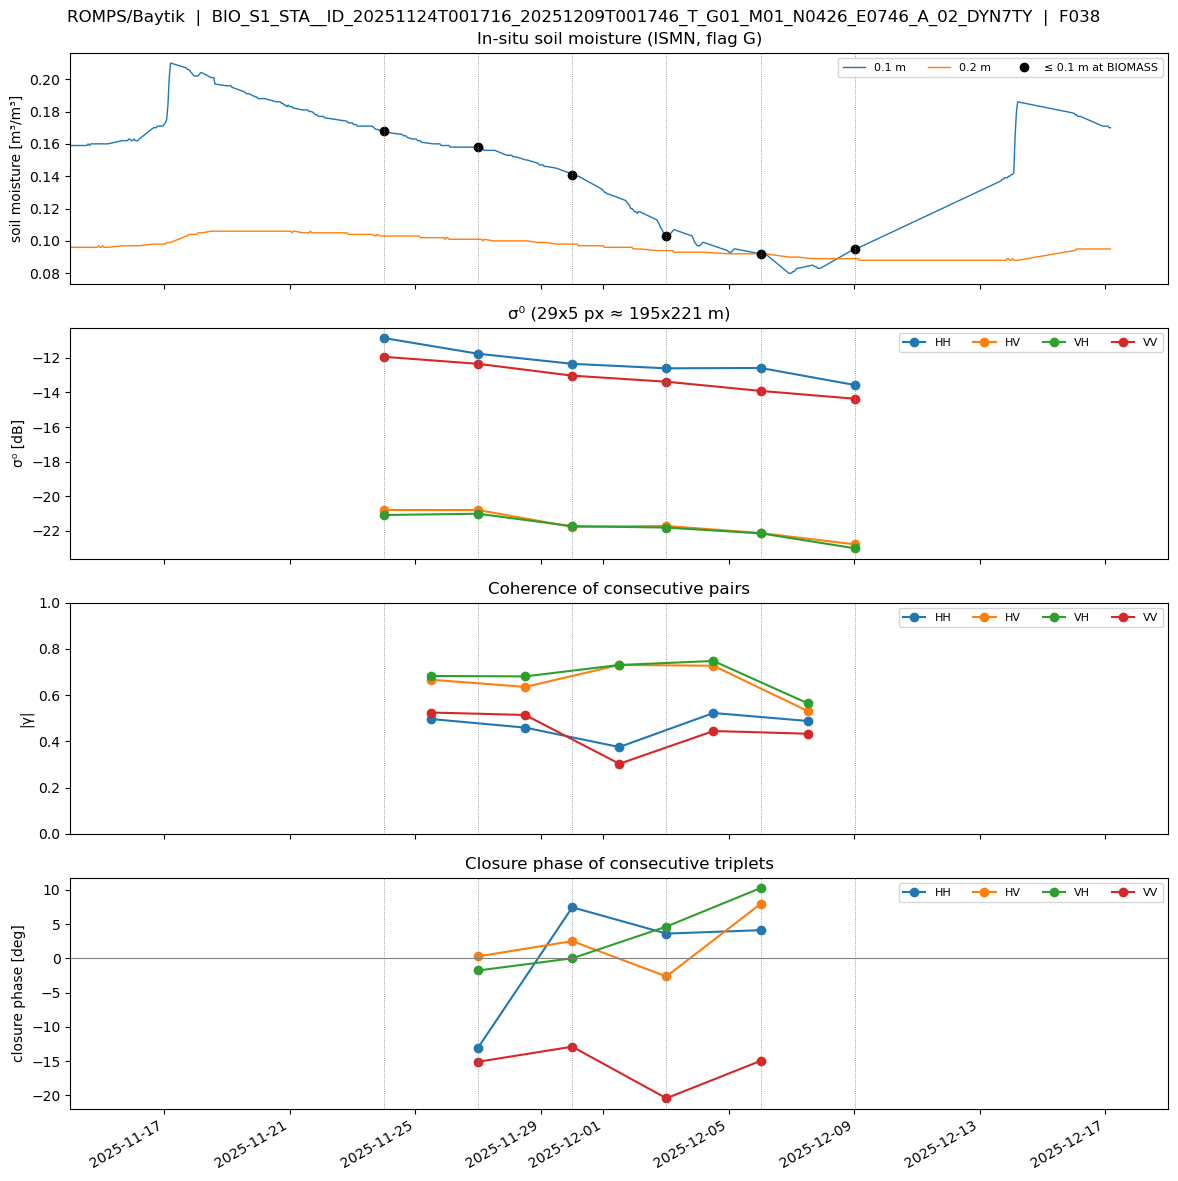

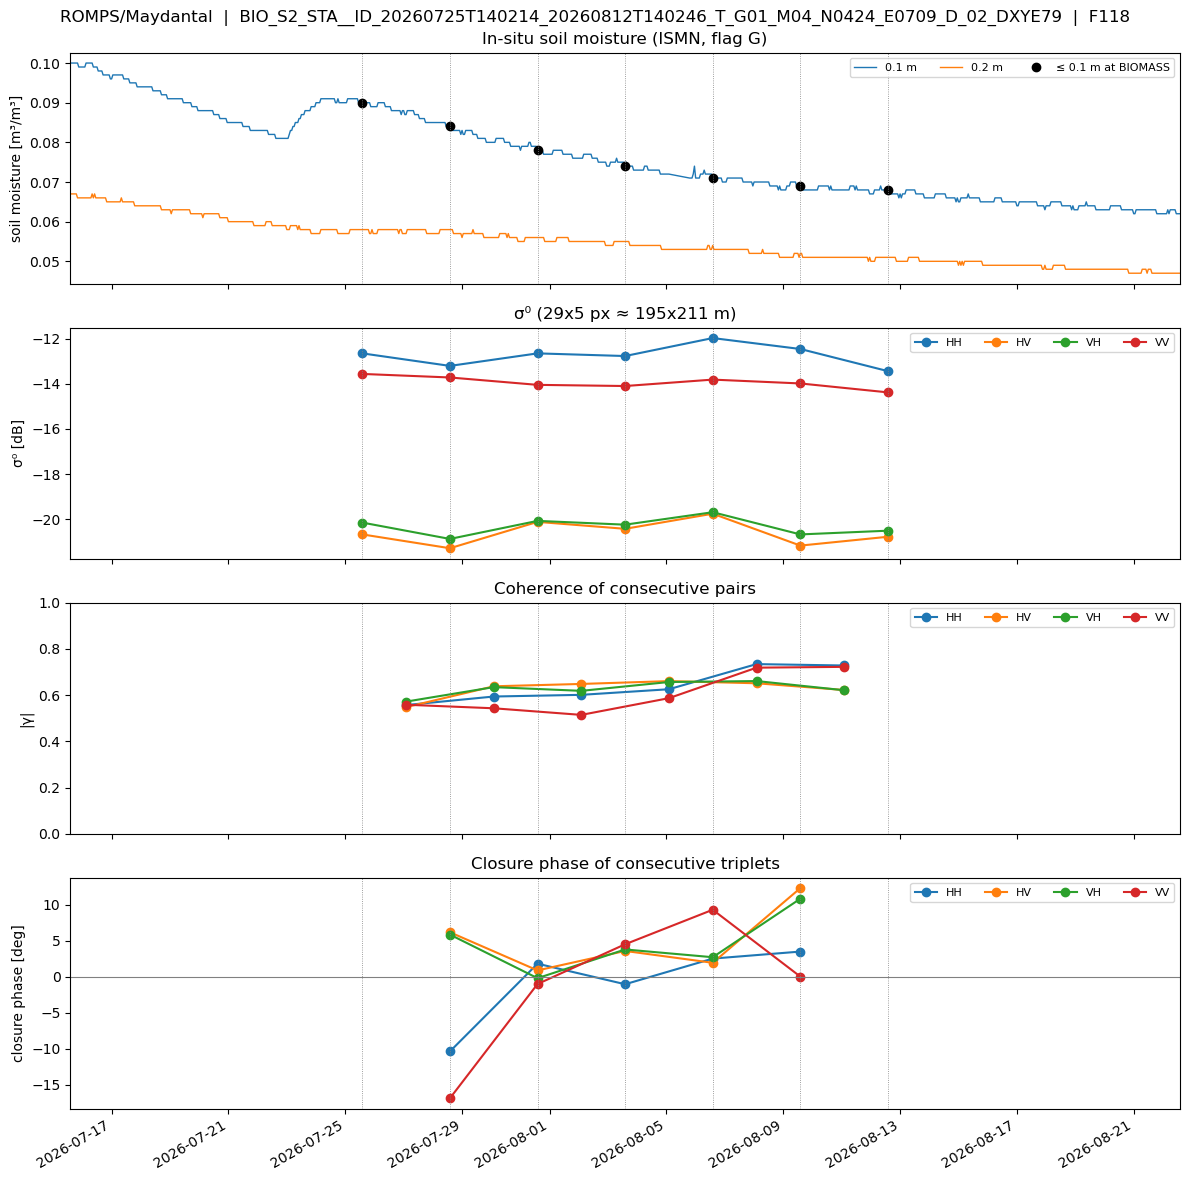

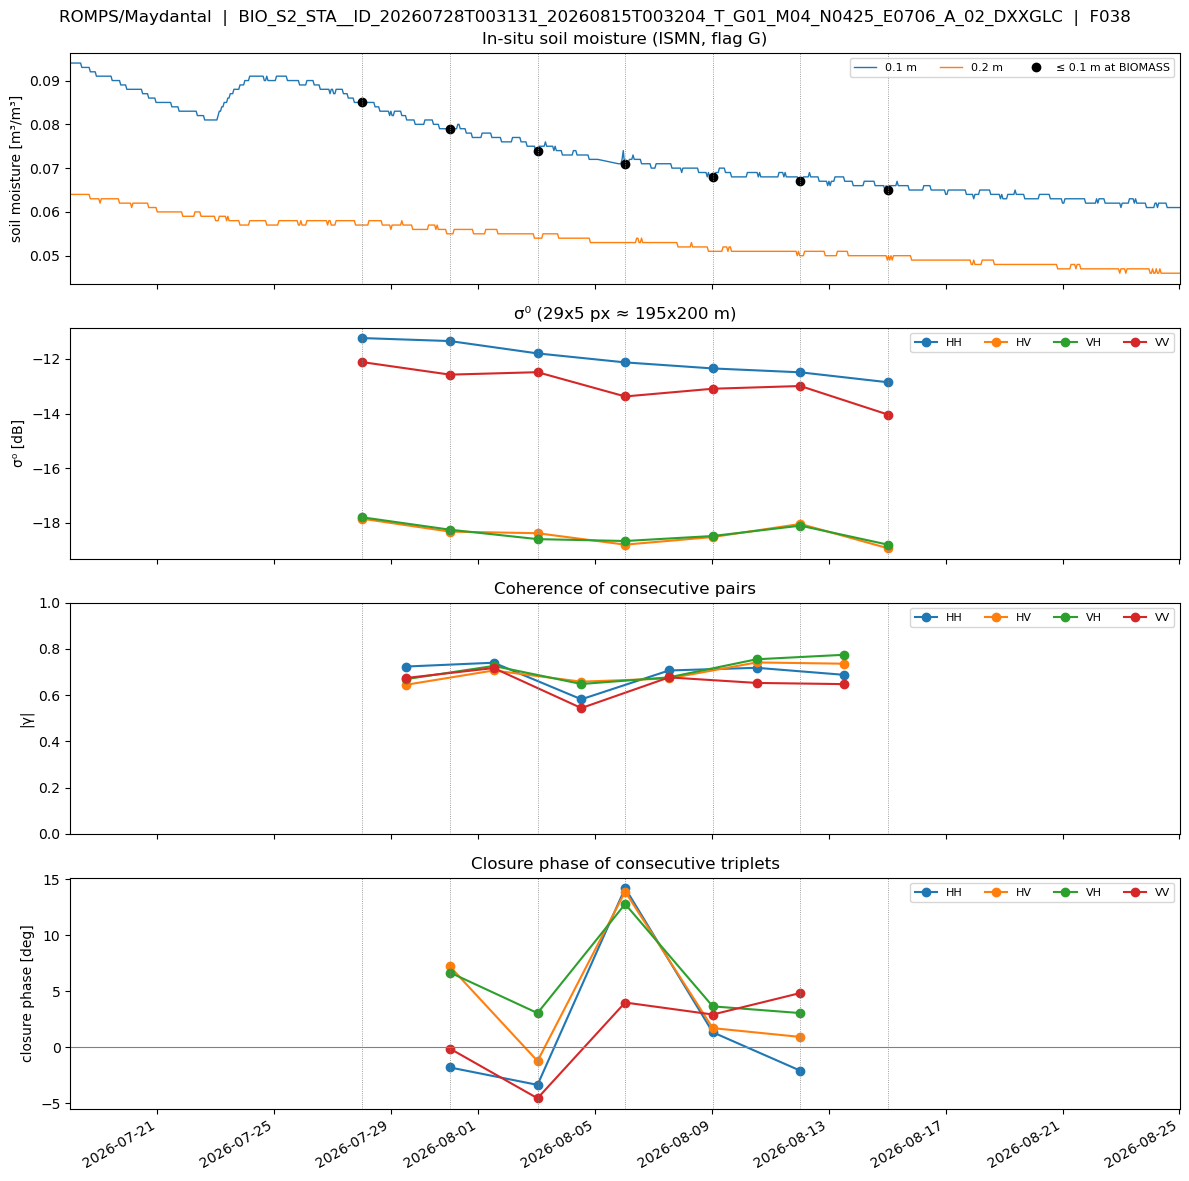

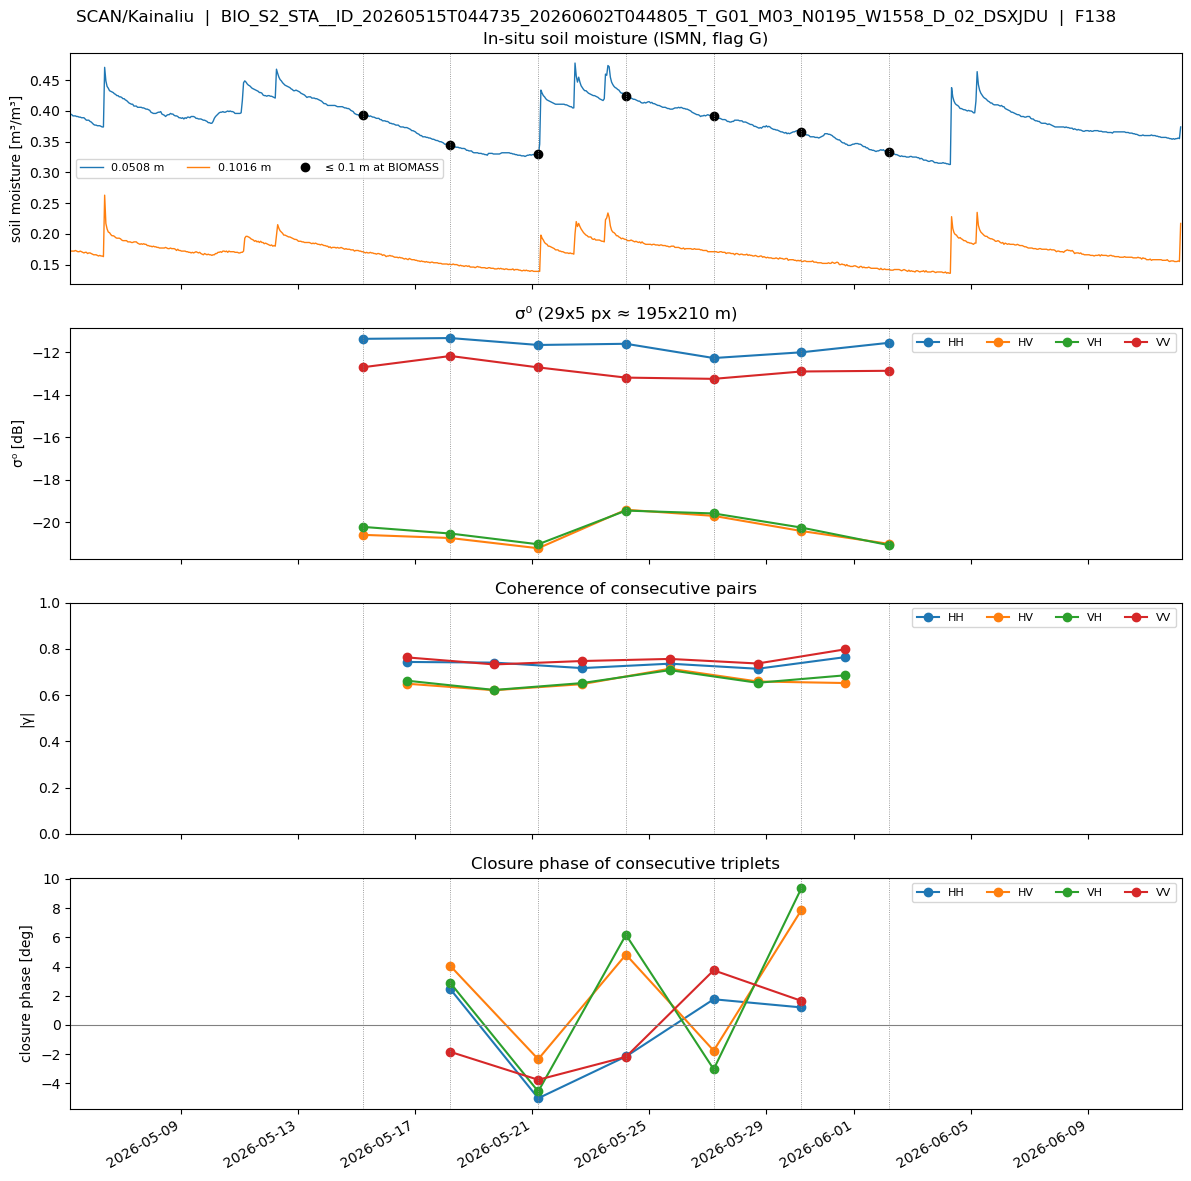

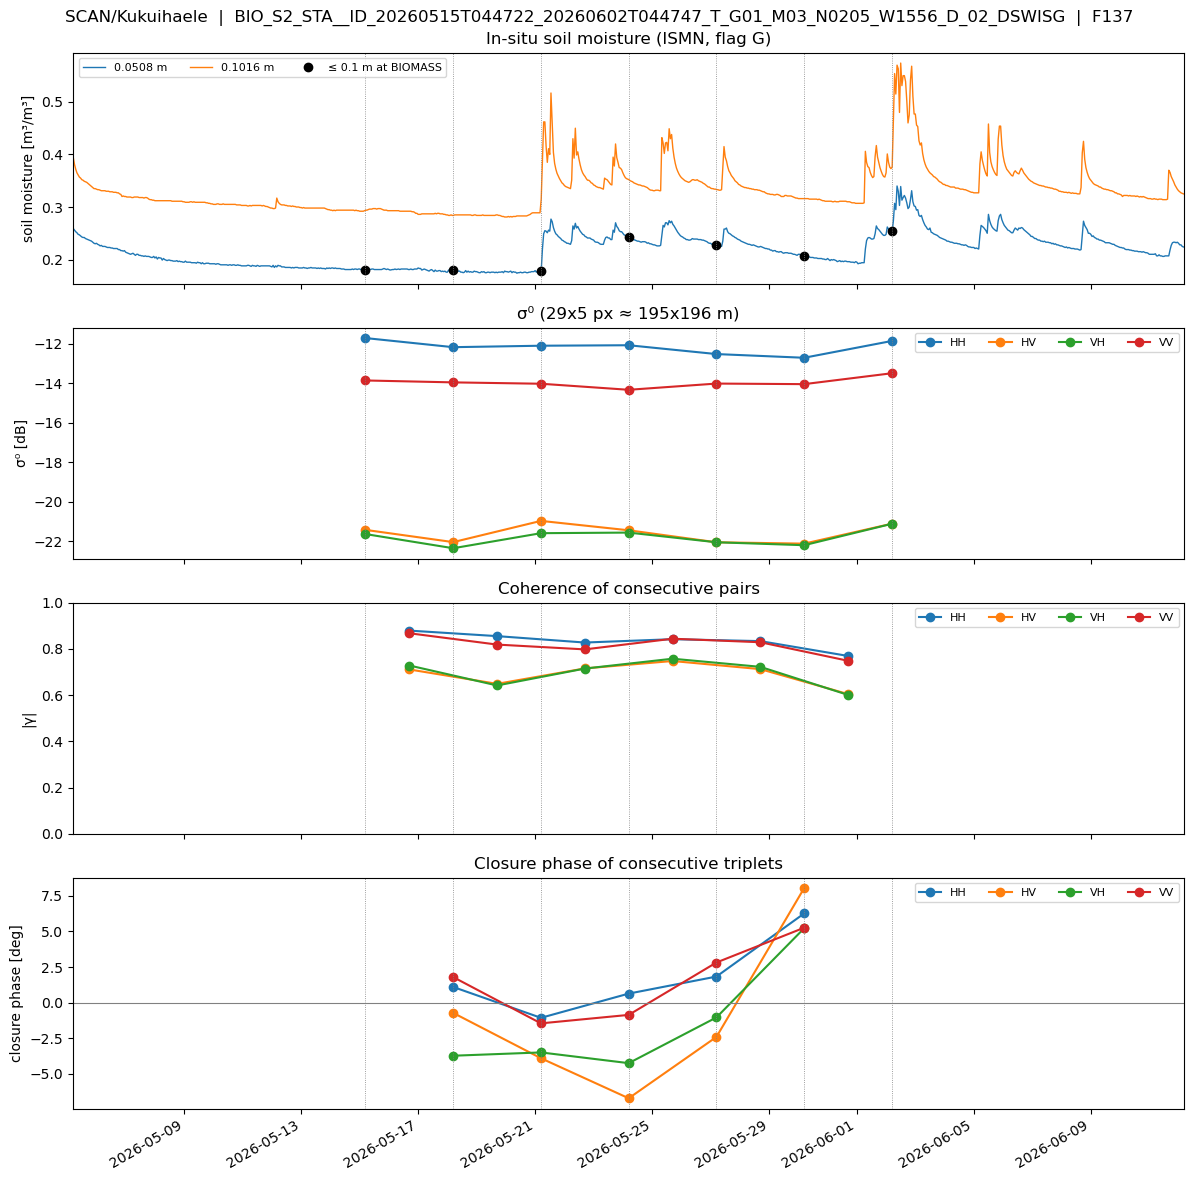

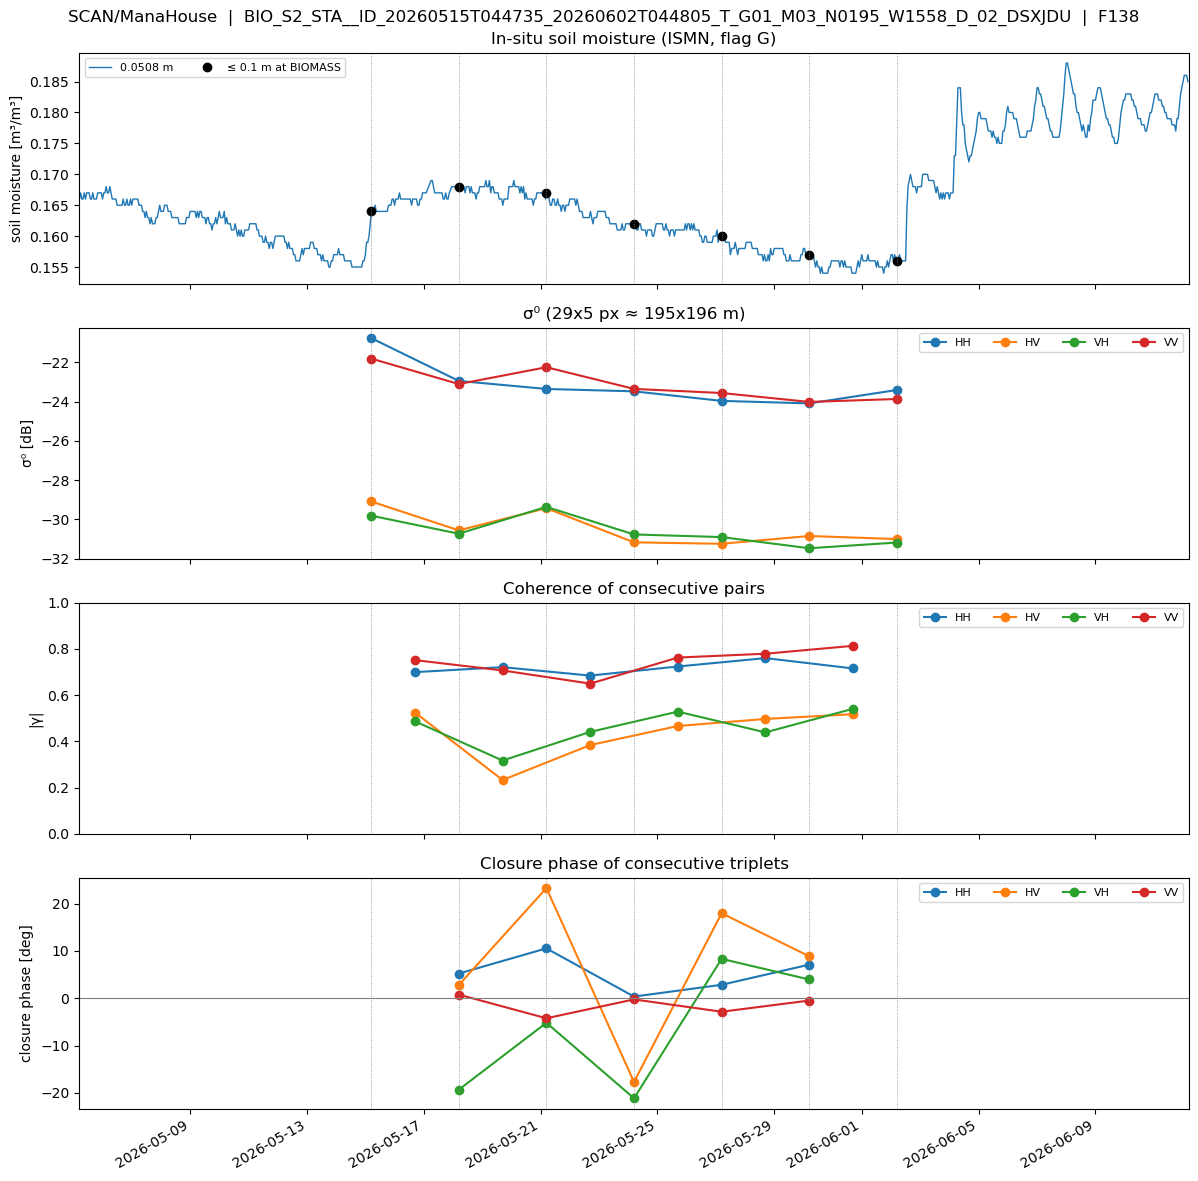

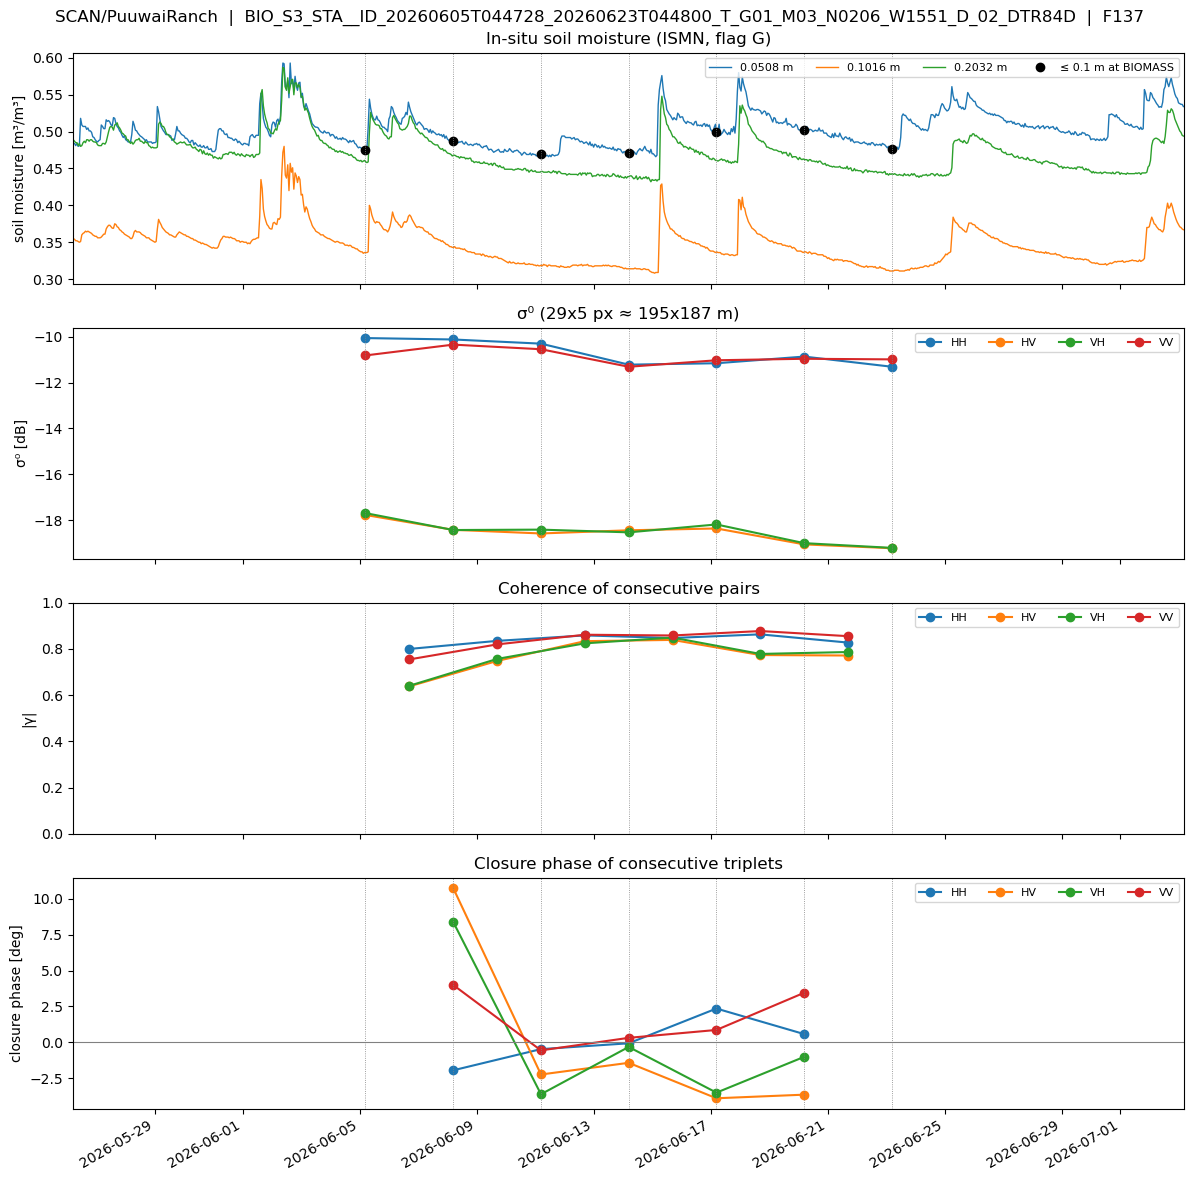

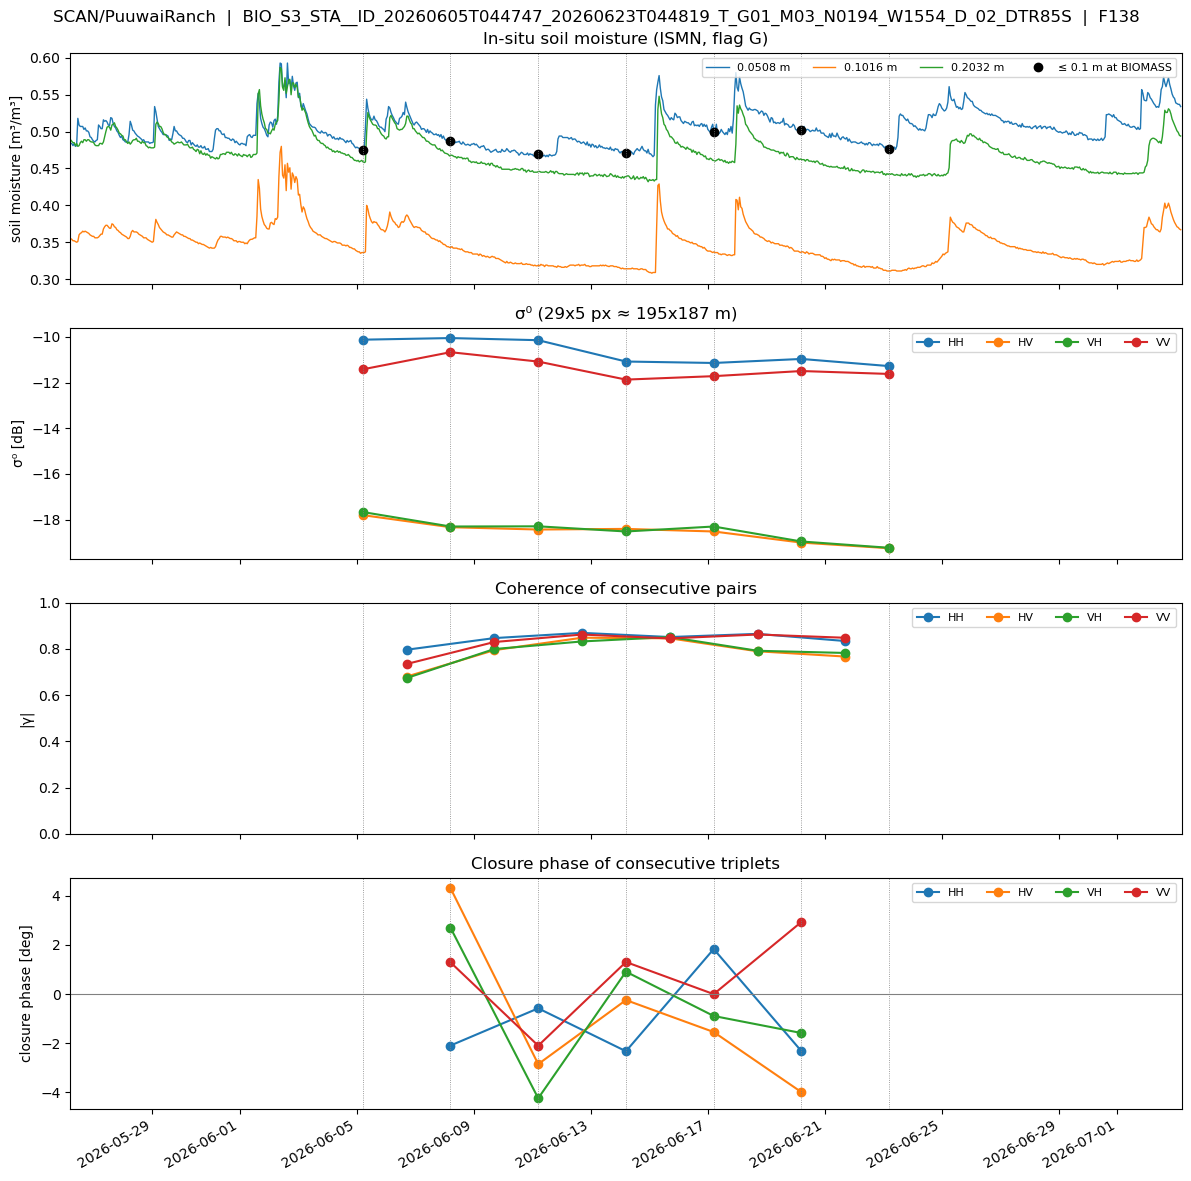

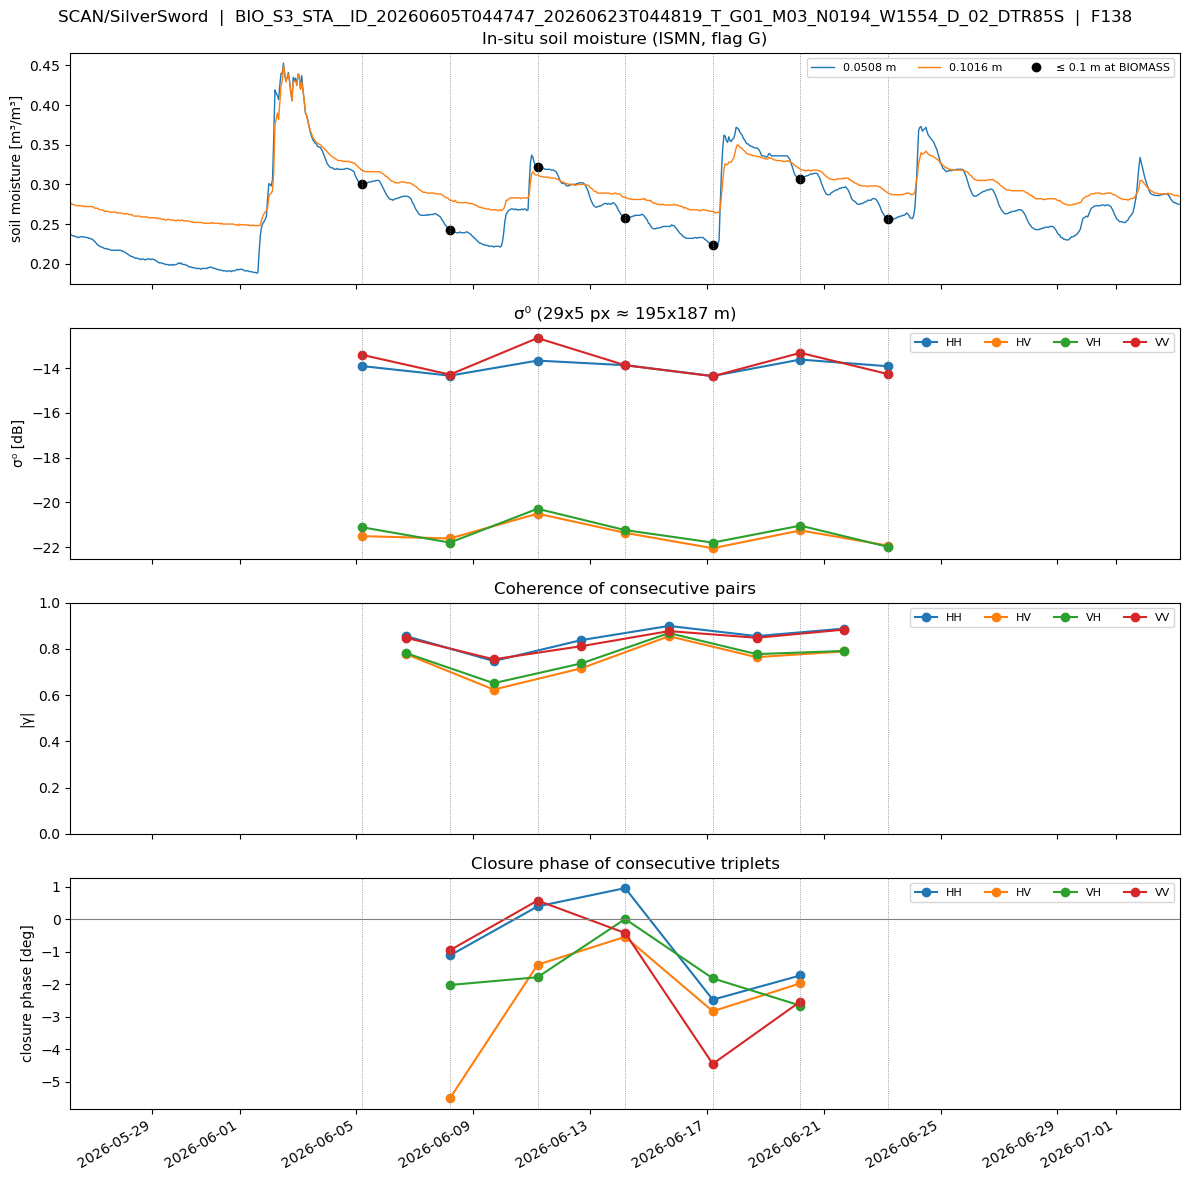

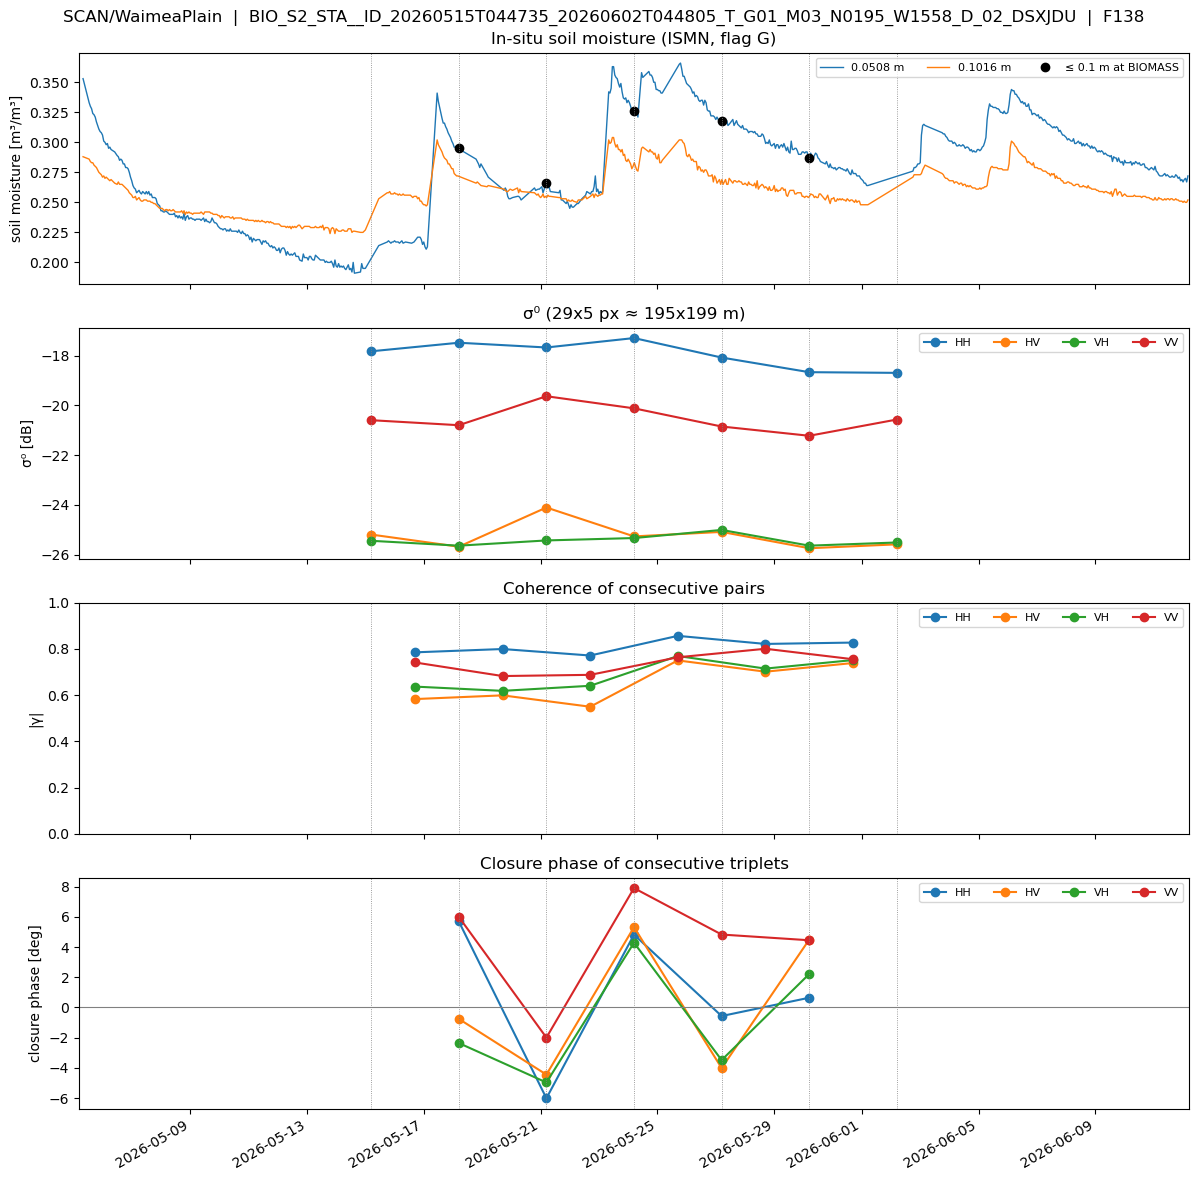

In [5]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
margin = pd.Timedelta(days=TIME_MARGIN_DAYS)

for _, loc in locations.iterrows():
    key = {c: loc[c] for c in STACK}
    sel = lambda df: df[(df[STACK] == pd.Series(key)).all(axis=1)]
    a, p, t, ep = sel(acq), sel(pairs), sel(trips), sel(epochs)
    if a.empty:
        continue

    fig, ax = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
    d = sm_data.get(loc["point_id"])
    t0, t1 = a["datetime"].min() - margin, a["datetime"].max() + margin
    if d is not None:
        w = d[d["good"] & (d["depth_to"] <= PLOT_MAX_DEPTH_M) & d["date_time"].between(t0, t1)]
        for depth, g in w.groupby("depth_to"):
            g = g.groupby("date_time")["soil_moisture"].mean()
            ax[0].plot(g.index, g.values, lw=1, label=f"{depth:g} m")
    ax[0].plot(ep["datetime"], ep["sm"], "ko", ms=6, label=f"≤ {SM_MAX_DEPTH_M:g} m at BIOMASS")
    ax[0].set(ylabel="soil moisture [m³/m³]", title="In-situ soil moisture (ISMN, flag G)")
    ax[0].legend(fontsize=8, ncol=4)

    for pol, g in a.groupby("pol"):
        ax[1].plot(g["datetime"], g["sigma0_db"], "o-", label=pol)
    ax[1].set(ylabel="σ⁰ [dB]",
              title=f"σ⁰ ({int(loc['window_lines'])}x{int(loc['window_samples'])} px ≈ "
                    f"{loc['window_az_m']:.0f}x{loc['window_gr_m']:.0f} m)")
    ax[1].legend(fontsize=8, ncol=4)

    cons = p[p["consecutive"]]
    for pol, g in cons.groupby("pol"):
        ax[2].plot(g["date_i"] + (g["date_j"] - g["date_i"]) / 2, g["coherence"], "o-", label=pol)
    ax[2].set(ylabel="|γ|", ylim=(0, 1), title="Coherence of consecutive pairs")
    ax[2].legend(fontsize=8, ncol=4)

    for pol, g in t[t["consecutive"]].groupby("pol"):
        ax[3].plot(g["date_j"], np.degrees(g["closure_phase_rad"]), "o-", label=pol)
    ax[3].axhline(0, color="grey", lw=0.8)
    ax[3].set(ylabel="closure phase [deg]", title="Closure phase of consecutive triplets")
    ax[3].legend(fontsize=8, ncol=4)

    for axx in ax:
        for tt in ep["datetime"]:
            axx.axvline(tt, color="grey", lw=0.6, ls=":")
    ax[3].set_xlim(t0, t1)
    ax[3].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    fig.autofmt_xdate()
    fig.suptitle(f"{loc['point_id']}  |  {loc['stack_id']}  |  F{loc['frame']}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"timeseries_{loc['point_id'].replace('/', '_')}_{loc['stack_id']}_F{loc['frame']}.png", dpi=120)
    plt.show()

### 6. σ⁰ vs soil moisture (all stations)

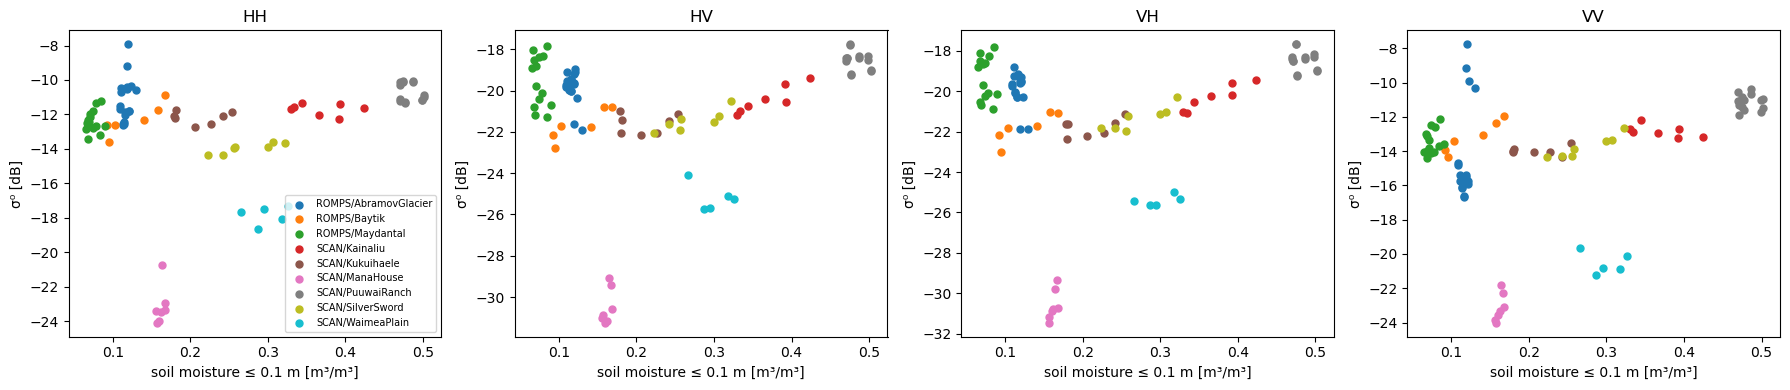

In [6]:
pols = sorted(acq["pol"].unique())
stations = sorted(acq["point_id"].unique())
colors = dict(zip(stations, plt.cm.tab10(np.linspace(0, 1, max(len(stations), 2)))))

fig, ax = plt.subplots(1, len(pols), figsize=(4.5 * len(pols), 4), sharey=False, squeeze=False)
for k, pol in enumerate(pols):
    for pid, g in acq[(acq["pol"] == pol) & acq["sm"].notna()].groupby("point_id"):
        ax[0, k].scatter(g["sm"], g["sigma0_db"], color=colors[pid], label=pid, s=25)
    ax[0, k].set(title=pol, xlabel=f"soil moisture ≤ {SM_MAX_DEPTH_M:g} m [m³/m³]", ylabel="σ⁰ [dB]")
ax[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "sigma0_vs_sm.png", dpi=120)

### 7. Pairs: coherence and interferometric phase vs soil moisture change

`dsm = sm_j − sm_i` for every pair (i earlier than j). The interferometric phase still contains the residual (non-topographic) geometric and ground-phase terms; it is shown for exploration.

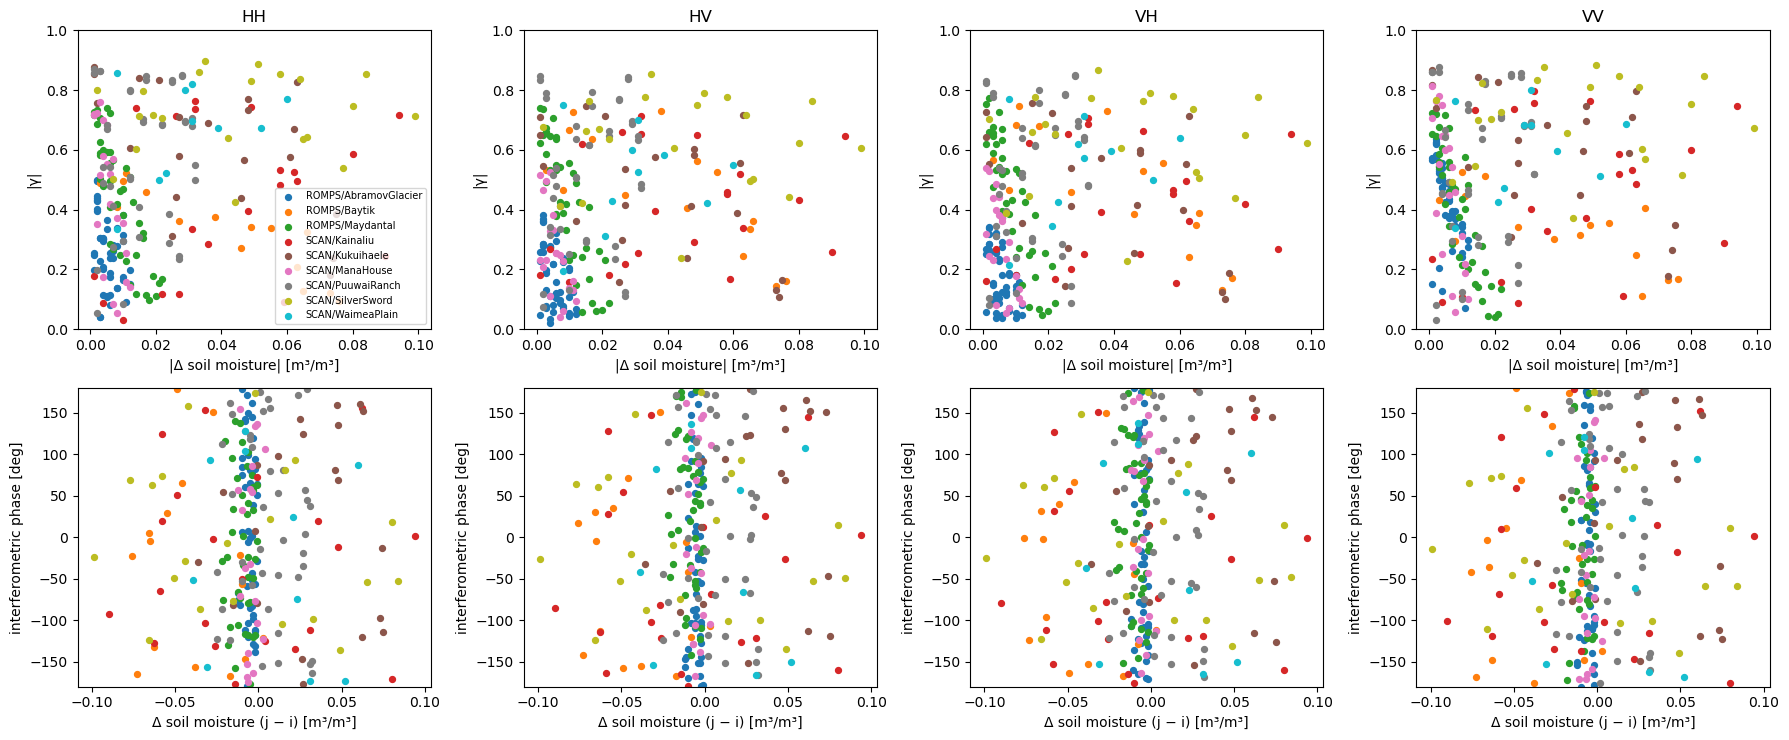

In [7]:
fig, ax = plt.subplots(2, len(pols), figsize=(4.5 * len(pols), 7.5), squeeze=False)
for k, pol in enumerate(pols):
    for pid, g in pairs[(pairs["pol"] == pol) & pairs["dsm"].notna()].groupby("point_id"):
        ax[0, k].scatter(g["dsm"].abs(), g["coherence"], color=colors[pid], label=pid, s=18)
        ax[1, k].scatter(g["dsm"], np.degrees(g["phase_rad"]), color=colors[pid], s=18)
    ax[0, k].set(title=pol, xlabel="|Δ soil moisture| [m³/m³]", ylabel="|γ|", ylim=(0, 1))
    ax[1, k].set(xlabel="Δ soil moisture (j − i) [m³/m³]", ylabel="interferometric phase [deg]", ylim=(-180, 180))
ax[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "pairs_vs_dsm.png", dpi=120)

### 8. Closure phase vs soil moisture change

Closure phase of every triplet (i < j < k) against `dsm_ik = sm_k − sm_i`; marker colour = station, filled markers = consecutive triplets.

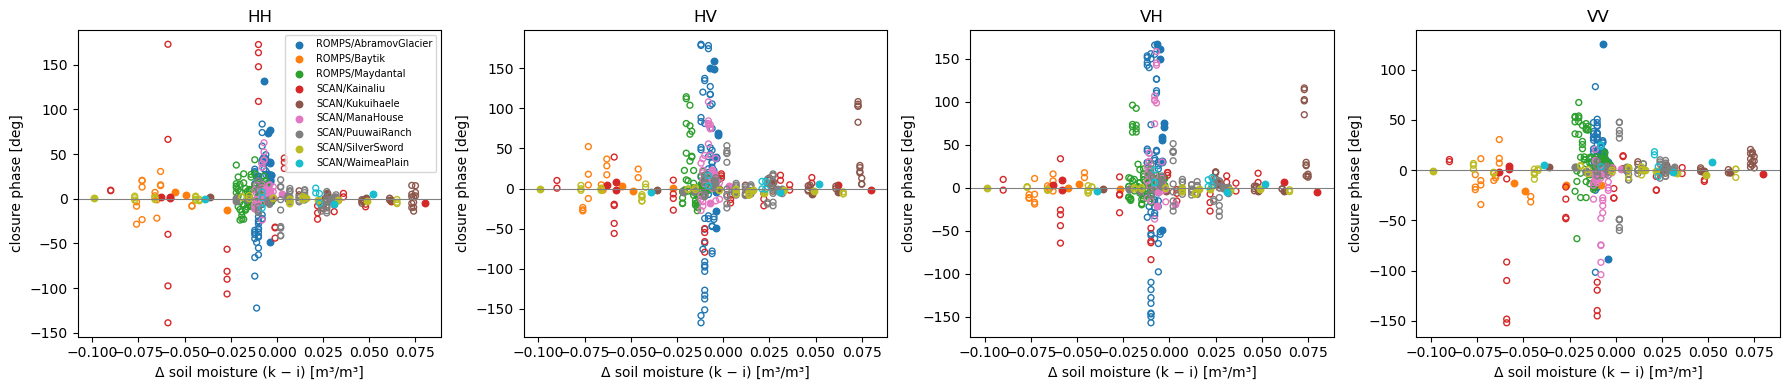

In [8]:
fig, ax = plt.subplots(1, len(pols), figsize=(4.5 * len(pols), 4), squeeze=False)
for k, pol in enumerate(pols):
    for pid, g in trips[(trips["pol"] == pol) & trips["dsm_ik"].notna()].groupby("point_id"):
        c = g["consecutive"].astype(bool)
        ax[0, k].scatter(g.loc[~c, "dsm_ik"], np.degrees(g.loc[~c, "closure_phase_rad"]),
                         facecolors="none", edgecolors=colors[pid], s=18)
        ax[0, k].scatter(g.loc[c, "dsm_ik"], np.degrees(g.loc[c, "closure_phase_rad"]),
                         color=colors[pid], s=22, label=pid)
    ax[0, k].axhline(0, color="grey", lw=0.8)
    ax[0, k].set(title=pol, xlabel="Δ soil moisture (k − i) [m³/m³]", ylabel="closure phase [deg]")
ax[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "closure_vs_dsm.png", dpi=120)

### 9. Summary per station and polarisation

In [9]:
rows = []
for (pid, pol), g in acq.groupby(["point_id", "pol"]):
    g = g.dropna(subset=["sm"])
    rows.append({
        "point_id": pid, "pol": pol, "n_with_sm": len(g),
        "sm_min": g["sm"].min(), "sm_max": g["sm"].max(),
        "sigma0_db_min": g["sigma0_db"].min(), "sigma0_db_max": g["sigma0_db"].max(),
        "r_sigma0_db_sm": g["sigma0_db"].corr(g["sm"]) if len(g) > 2 else np.nan,
    })
summary = pd.DataFrame(rows)
summary.to_csv(FIG_DIR / "summary_sigma0_sm.csv", index=False)
print(f"Figures and summary saved to {FIG_DIR.resolve()}")
summary.round(3)

Figures and summary saved to /media/kle/cropg_hd1/biomass-hackathon-2026-output/figures


,point_id,pol,n_with_sm,sm_min,sm_max,sigma0_db_min,sigma0_db_max,r_sigma0_db_sm
0,ROMPS/AbramovGlacier,HH,18,0.109,0.130,-12.595,-7.927,0.360
1,ROMPS/AbramovGlacier,HV,18,0.109,0.130,-21.896,-18.938,-0.433
2,ROMPS/AbramovGlacier,VH,18,0.109,0.130,-21.864,-18.815,-0.487
3,ROMPS/AbramovGlacier,VV,18,0.109,0.130,-16.702,-7.761,0.530
4,ROMPS/Baytik,HH,6,0.092,0.168,-13.571,-10.859,0.868
5,ROMPS/Baytik,HV,6,0.092,0.168,-22.783,-20.798,0.880
6,ROMPS/Baytik,VH,6,0.092,0.168,-23.008,-21.014,0.853
7,ROMPS/Baytik,VV,6,0.092,0.168,-14.365,-11.942,0.951
8,ROMPS/Maydantal,HH,14,0.065,0.090,-13.440,-11.234,0.215
9,ROMPS/Maydantal,HV,14,0.065,0.090,-21.290,-17.848,-0.177
